# UK retail performance

Decision: reconcile revenue and identify customer activity requiring investigation. This walkthrough uses generated synthetic transactions for repeatable offline execution. See `artifacts/full/retail_case_study.md` for full-population results. Source: Chen (2015), UCI Online Retail, DOI 10.24432/C5BW33, CC BY 4.0. Built with AI assistance.

In [1]:
from pathlib import Path

import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUN = ROOT / "artifacts/demo"
print("Retail and churn mode: seeded synthetic offline demo. Logistics: synthetic.")

Retail and churn mode: seeded synthetic offline demo. Logistics: synthetic.


## 1. Profile and clean the source

Keep missing customer IDs in revenue. Keep negative credits. Explain every excluded row.

In [2]:
from portfolio.retail import clean_retail
from portfolio.synthetic import retail_demo

raw = retail_demo()
clean, audit = clean_retail(raw)
pd.Series(audit)

input_rows                                                                      12088
exact_duplicates_removed                                                           55
invalid_rows_removed_after_dedup                                                    5
retained_rows                                                                   12028
missing_customer_rows_retained                                                   1572
gross_sales_gbp                                                             633224.49
credits_gbp                                                                  45914.67
net_revenue_gbp                                                             587309.82
duplicate_policy                    Remove exact duplicate rows; alternative polic...
dtype: object

In [3]:
assert (
    audit["input_rows"]
    == audit["retained_rows"]
    + audit["exact_duplicates_removed"]
    + audit["invalid_rows_removed_after_dedup"]
)
assert abs(clean.line_value.sum() - audit["net_revenue_gbp"]) < 1e-6
print("Row audit and signed revenue reconcile.")

Row audit and signed revenue reconcile.


## 2. Execute the analytical SQL

The same SQL builds the application marts. Credits do not create positive orders. RFM excludes only unidentified customers and non-purchase activity.

In [4]:
import duckdb

con = duckdb.connect()
con.register("fact_retail", clean)
con.execute((ROOT / "src/portfolio/queries/retail.sql").read_text())
monthly = con.sql("SELECT * FROM mart_retail_monthly ORDER BY month").df()
monthly

,month,gross_sales_gbp,credits_gbp,net_revenue_gbp,orders,gross_order_value_gbp,net_revenue_mom,complete_month
0,2025-01-01,52318.47,3082.19,49236.28,219.0,238.897123,NaN,True
1,2025-02-01,48656.91,3144.63,45512.28,226.0,215.296062,-0.075635,True
2,2025-03-01,55211.08,3354.62,51856.46,247.0,223.526640,0.139395,True
3,2025-04-01,53646.74,3878.19,49768.55,241.0,222.600581,-0.040263,True
4,2025-05-01,53537.41,4507.30,49030.11,238.0,224.947101,-0.014837,True
5,2025-06-01,52278.56,4077.19,48201.37,242.0,216.027107,-0.016903,True
6,2025-07-01,51089.62,5294.36,45795.26,224.0,228.078661,-0.049918,True
7,2025-08-01,59156.79,4044.28,55112.51,278.0,212.794209,0.203454,True
8,2025-09-01,50138.76,4486.13,45652.63,216.0,232.123889,-0.171647,True
9,2025-10-01,56232.42,4560.69,51671.73,252.0,223.144524,0.131846,True


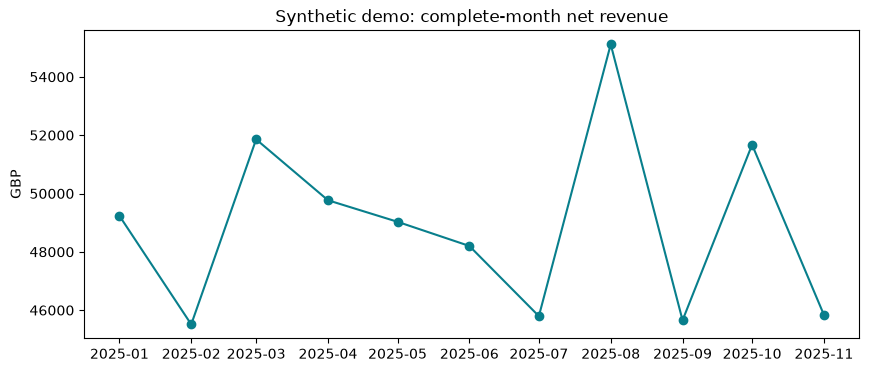

In [5]:
import matplotlib.pyplot as plt

complete = monthly[monthly.complete_month]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(complete.month, complete.net_revenue_gbp, marker="o", color="#087f8c")
ax.set(title="Synthetic demo: complete-month net revenue", ylabel="GBP")
plt.show()

In [6]:
segments = con.sql(
    "SELECT segment, COUNT(*) AS customers, SUM(monetary_gbp) AS gross_sales_gbp FROM mart_retail_rfm GROUP BY segment ORDER BY customers DESC"
).df()
segments

,segment,customers,gross_sales_gbp
0,Loyal active,318,437792.93
1,Loyal lapsed,89,97281.47
2,Occasional lapsed,27,8708.39
3,Recent occasional,14,5351.37


In [7]:
cohorts = con.sql("SELECT * FROM mart_retail_cohorts").df()
cohorts.pivot(index="cohort_month", columns="month_index", values="retention").round(2)

month_index,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2025-01-01,1.0,0.33,0.40,0.34,0.40,0.32,0.42,0.42,0.31,0.41,0.35,0.36
2025-02-01,1.0,0.37,0.38,0.35,0.44,0.37,0.42,0.34,0.36,0.33,0.31,NaN
2025-03-01,1.0,0.41,0.36,0.29,0.32,0.52,0.40,0.33,0.29,0.32,NaN,NaN
2025-04-01,1.0,0.38,0.35,0.35,0.20,0.30,0.42,0.28,0.42,NaN,NaN,NaN
2025-05-01,1.0,0.59,0.37,0.52,0.33,0.30,0.37,0.19,NaN,NaN,NaN,NaN
2025-06-01,1.0,0.33,0.44,0.28,0.44,0.61,0.33,NaN,NaN,NaN,NaN,NaN
2025-07-01,1.0,0.14,0.29,0.71,0.43,0.43,NaN,NaN,NaN,NaN,NaN,NaN
2025-08-01,1.0,NaN,0.38,0.38,0.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-09-01,1.0,NaN,0.50,0.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Decision and limits

Investigate credit reasons before changing return policy. Pilot reactivation with a randomised control group. Cohorts use first observed purchase, so they do not prove acquisition or contractual churn. December 2011 is partial. Synthetic totals do not describe a real retailer. No margin or actual campaign outcomes are available.

In [8]:
con.close()
print((RUN / "retail_case_study.md").read_text())

# Synthetic retail demonstration

The seed-42 generator produced 12,088 artificial transaction lines.
This offline run exercises data contracts, signed revenue, SQL marts, segment totals
and cohort calculations. No record represents an actual customer.

Computed synthetic gross sales: £633,224.49.
Computed synthetic credits: £45,914.67.
Computed synthetic net revenue: £587,309.82.

The quality audit retains 12,028 rows. Input rows reconcile to
retained rows plus duplicate and invalid exclusions. Individual details are generated
locally. The public snapshot contains only aggregate results.

Use `portfolio build --source full` for the separate historical UCI case study.
The full-data decision memo is in `artifacts/full/retail_case_study.md`.

